In [18]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris=load_iris()
X=StandardScaler().fit_transform(iris.data)
y=iris.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
X_train = X_train.astype(np.float32)

In [19]:
W1=tf.Variable(tf.random.normal((4,16)))
b1=tf.Variable(tf.zeros(16))
W2=tf.Variable(tf.random.normal((16,3)))
b2=tf.Variable(tf.zeros(3))

def forward(x):
    h=tf.nn.relu(tf.matmul(x,W1)+b1)
    return tf.nn.softmax(tf.matmul(h,W2)+b2)

print(forward(X_train[:2]))

tf.Tensor(
[[1.4628778e-03 9.6978806e-04 9.9756742e-01]
 [5.0246132e-09 9.9476445e-01 5.2355602e-03]], shape=(2, 3), dtype=float32)


In [20]:
acts={
'Sigmoid':'sigmoid',
'Tanh':'tanh',
'ReLU':'relu',
'Leaky ReLU':tf.nn.leaky_relu,
'ELU':'elu'
}

In [21]:
results={}

for name,act in acts.items():
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16,activation=act),
        tf.keras.layers.Dense(3,activation='softmax')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    t=time.time() if False else 0
    history=model.fit(X_train,y_train,epochs=5,batch_size=16,
                      validation_data=(X_test,y_test),verbose=0)
    results[name]=(history.history['loss'][-1],
                   history.history['val_accuracy'][-1],
                   history.history['loss'])
    print(name,"Loss:",results[name][0],
          "Accuracy:",results[name][1]*100)

Sigmoid Loss: 1.1582436561584473 Accuracy: 30.000001192092896
Tanh Loss: 0.6319106817245483 Accuracy: 83.33333134651184
ReLU Loss: 0.7340256571769714 Accuracy: 93.33333373069763
Leaky ReLU Loss: 1.1933387517929077 Accuracy: 36.666667461395264
ELU Loss: 1.452636957168579 Accuracy: 10.000000149011612


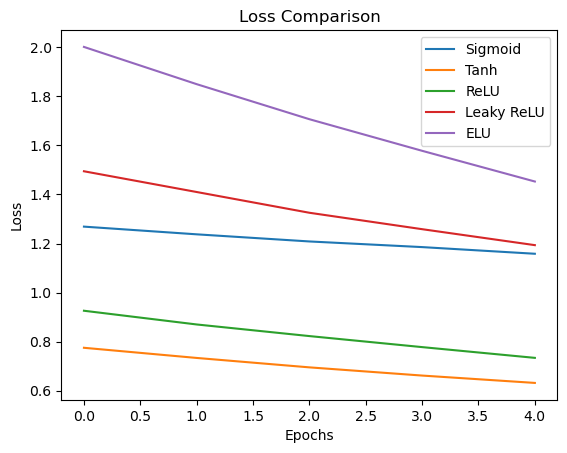

In [22]:
for name,r in results.items():
    plt.plot(r[2],label=name)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Comparison")
plt.legend()
plt.show()

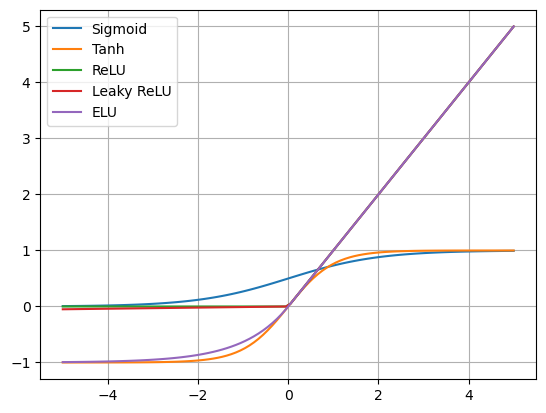

In [23]:
x=np.linspace(-5,5,100)

plt.plot(x,1/(1+np.exp(-x)),label='Sigmoid')
plt.plot(x,np.tanh(x),label='Tanh')
plt.plot(x,np.maximum(0,x),label='ReLU')
plt.plot(x,np.maximum(0.01*x,x),label='Leaky ReLU')
plt.plot(x,np.where(x>0,x,np.exp(x)-1),label='ELU')

plt.legend()
plt.grid()
plt.show()

In [25]:
import time
results={}

for name,act in acts.items():
    model=tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16,activation=act),
        tf.keras.layers.Dense(3,activation='softmax')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    start=time.time()
    history=model.fit(X_train,y_train,epochs=5,batch_size=16,
                      validation_data=(X_test,y_test),verbose=0)
    elapsed=time.time()-start

    results[name]=(history.history['loss'][-1],
                   history.history['val_accuracy'][-1],
                   history.history['loss'])

    print(name,"Loss:",results[name][0],
          "Accuracy:",results[name][1]*100,
          "Time:",elapsed)

Sigmoid Loss: 1.0309518575668335 Accuracy: 69.9999988079071 Time: 2.6268365383148193
Tanh Loss: 1.0210050344467163 Accuracy: 50.0 Time: 2.8848395347595215
ReLU Loss: 1.405210018157959 Accuracy: 30.000001192092896 Time: 3.4578640460968018
Leaky ReLU Loss: 0.8570861220359802 Accuracy: 69.9999988079071 Time: 2.910876750946045
ELU Loss: 0.6591705679893494 Accuracy: 69.9999988079071 Time: 2.720139265060425
